# Arm control

The table turns between the sides of the block and the arm carves each side with the table still.

Here we choose the number of sides and then build the resolved-rate controller that moves the chisel from cube to cube.

## Setup

In [1]:
import warnings

# A few docstrings in the toolbox trigger SyntaxWarnings when Python compiles them; not related to our code
warnings.filterwarnings("ignore", category=SyntaxWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import roboticstoolbox as rtb
from sculptor.carving import DT, carving_order, side_of, solve_poses, table_angles
from sculptor.cell import N_SIDES, Cell
from sculptor.collision import Hitboxes
from sculptor.controller import TOLERANCE, rrmc
from sculptor.model import STATUE_HEIGHT, proxy_pawn

# Seed of the random restarts of the inverse kinematics (reproducibility purposes)
IK_SEED: int = 0

# One color per controller in the plots
VARIANT_COLORS = {"position only": "#b0233a", "posture toward IK": "#c27c00", "position and axis": "#008a7a"}

panda = rtb.models.Panda()
cell = Cell()
voxels = proxy_pawn(STATUE_HEIGHT)
hitboxes = Hitboxes(panda, cell)

## 1. Sides of the block

In notebook 03 the table turned every cube to the front of the robot, so the table did most of the work and the arm barely moved. Here the block has a few sides. The table shows one side and the arm carves all the marble of that side in the current layer before the table turns again. A cube belongs to the side its angle around the axis of the table is closest to, and inside a side the arm starts with the cubes closest to the robot.

For each case, we count the blocked cubes as in notebook 03 and how much the table and the arm move: the sum of the changes of the table angle and of the joints from one cube to the next. These sums only compare the cases; the real motion comes with the controller.

In [2]:
def compare(order: np.ndarray, phi: np.ndarray) -> dict:
    """Blocked cubes and how much the table and the arm move along an order."""
    q = solve_poses(panda, cell, voxels, order, phi, seed=IK_SEED)
    # The table can turn either way, so each change of angle takes the short way, between -pi and pi
    turns = np.angle(np.exp(1j * np.diff(phi))) # memo: j is the imaginary number i (sqrt(-1))
    return {"blocked": len(hitboxes.blocked(voxels, order, phi, q)),
            "table turns": int(np.sum(~np.isclose(turns, 0.0))),
            "table path [rad]": np.abs(turns).sum(),
            "arm path [rad]": np.linalg.norm(np.diff(q, axis=0), axis=1).sum()}

In [3]:
rows: dict = {}
for name, n_sides in {"one turn per cube": None, "4 sides": 4, "8 sides": 8}.items():
    order = carving_order(voxels, n_sides)
    rows[name] = compare(order, table_angles(voxels, order, cell, n_sides))
    
# 4 sides, but each side from the outside in, like the layers of notebook 03
side = side_of(voxels.centers, 4)
r = np.hypot(voxels.centers[:, 0], voxels.centers[:, 1])
order = np.lexsort((-r, side, -voxels.centers[:, 2]))
order = order[~voxels.is_statue[order]]
rows["4 sides, outside in"] = compare(order, table_angles(voxels, order, cell, 4))

pd.DataFrame.from_dict(rows, orient="index").round(1)

,blocked,table turns,table path [rad],arm path [rad]
one turn per cube,8,1603,3189.5,30.0
4 sides,8,59,92.7,365.4
8 sides,86,119,93.5,347.1
"4 sides, outside in",8,59,92.7,814.3


With **one turn per cube** the table turns $1603$ times and covers $3189.5$ rad, while the arm covers $30.0$ rad.       
With **4 sides** the table turns $59$ times and covers $92.7$ rad, the arm covers $365.4$ rad, and the same 8 cubes stay blocked, so most of the motion moves from the table to the arm.        
**8 sides** block $86$ cubes with about the same table path ($93.5$ rad).       
**Inside a side, going from the outside** in more than doubles the arm path ($814.3$ rad) with the same blocked cubes.

We use **4 sides** (`N_SIDES` in `src/sculptor/cell.py`) and inside each side the cubes closest to the robot first (`carving_order` in `src/sculptor/carving.py`).

## 2. Resolved-rate control

The controller is the closed-loop resolved-rate motion control of lecture 6 (Robot Controls), applied to the chisel tip, with the posture task in the null space.

$$\dot{\mathbf{q}} = \lambda \mathbf{J}^+ (\mathbf{x}^\ast - \mathbf{k}(\mathbf{q})) + (\mathbf{I} - \mathbf{J}^+\mathbf{J})\, k_0 (\mathbf{q}_r - \mathbf{q})$$

In the lecture the task is only the position. Here the direction of the chisel matters too, since the tilt of notebook 03 is what lets it reach every cube without hitting the block. We compare three versions:

- position only, as in the lecture;
- position only, with the IK pose of the target cube as posture reference instead of $\mathbf{q}_r$, so the posture task also pulls the chisel to the right direction;
- position and axis of the chisel. If $\mathbf{a}$ is the current axis and $\mathbf{a}^\ast$ the target one, $\mathbf{a} \times \mathbf{a}^\ast$ is the rotation that brings one onto the other, so it plays the role of $\mathbf{x}^\ast - \mathbf{k}(\mathbf{q})$ for the direction. It goes under the position error, with the full Jacobian of the tip (6 x 7).

The gains are the ones of lecture 6 ($\lambda = 3$, $k_0 = 2$, in `src/sculptor/controller.py`), and the next target is taken when the tip is within 1 mm of the current one. The tip goes over the cubes of one side in two layers, the top one and the one in the middle, with the table still.

In [4]:
order = carving_order(voxels)
phi = table_angles(voxels, order, cell)
q_ik = solve_poses(panda, cell, voxels, order, phi, seed=IK_SEED)
layer_z = voxels.centers[order, 2]
side = side_of(voxels.centers[order], N_SIDES)


def first_side(z: float) -> np.ndarray:
    """Positions in the order of the cubes of the first side carved in the layer at height z."""
    in_layer = np.flatnonzero(np.isclose(layer_z, z))
    return in_layer[side[in_layer] == side[in_layer[0]]]


layers = np.unique(layer_z)
segments = {"top layer": first_side(layers[-1]), "middle layer": first_side(layers[len(layers) // 2])}
pd.DataFrame({"cubes": [len(ks) for ks in segments.values()],
              "z [m]": [layer_z[ks[0]] for ks in segments.values()]},
             index=list(segments)).round(3)

,cubes,z [m]
top layer,36,0.435
middle layer,32,0.225


In [5]:
# Whether the axis is in the task and whether the posture goes toward the IK pose instead of qr
VARIANTS = {"position only": (False, False), "posture toward IK": (False, True), "position and axis": (True, False)}
MAX_STEPS = 400


def follow(ks: np.ndarray, axis: bool, toward_ik: bool) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """The tip goes over the cubes ks of the order, starting at the IK pose of the first one.
    
    Returns the axis error at every step [deg], the axis error on arrival at each cube [deg],
    and the steps each move takes.
    """
    q = q_ik[ks[0]].copy()
    axis_error, arrival, steps = [], [], []
    for k in ks[1:]:
        assert phi[k] == phi[ks[0]], "the table must stay still inside a side"
        target = cell.tip_target(cell.block_to_world(voxels.centers[order[k]], phi[k])[0])
        q_posture = q_ik[k] if toward_ik else panda.qr
        for n in range(1, MAX_STEPS + 1):
            q = q + rrmc(panda, cell, q, target, q_posture, axis=axis) * DT
            T = panda.fkine(q, tool=cell.tip)
            axis_error.append(np.degrees(np.arccos(np.clip(T.R[:, 2] @ target.R[:, 2], -1.0, 1.0))))
            if np.linalg.norm(target.t - T.t) < TOLERANCE:
                break
        assert n < MAX_STEPS, f"cube {order[k]} not reached"
        steps.append(n)
        arrival.append(axis_error[-1])
    return np.array(axis_error), np.array(arrival), np.array(steps)


runs = {(seg, name): follow(ks, *VARIANTS[name]) for seg, ks in segments.items() for name in VARIANTS}
pd.DataFrame([{"layer": seg, "controller": name, "steps per cube": s.mean(), "most steps": s.max(),
               "largest axis error [deg]": e.max(), "largest on arrival [deg]": a.max()}
              for (seg, name), (e, a, s) in runs.items()]).set_index(["layer", "controller"]).round(2)

steps per cube  most steps  \
layer        controller                                      
top layer    position only               23.06          35   
             posture toward IK           23.00          35   
             position and axis           23.00          35   
middle layer position only               23.13          35   
             posture toward IK           24.10          59   
             position and axis           22.94          35   

                                largest axis error [deg]  \
layer        controller                                    
top layer    position only                         16.10   
             posture toward IK                      1.97   
             position and axis                      0.22   
middle layer position only                         35.24   
             posture toward IK                     67.19   
             position and axis                      0.87   

                                largest on arrival [deg]  
layer        controller                                   
top layer    position only                         16.10  
             posture toward IK                      0.23  
             position and axis                      0.01  
middle layer position only                         35.23  
             posture toward IK                      4.00  
             position and axis                      0.01

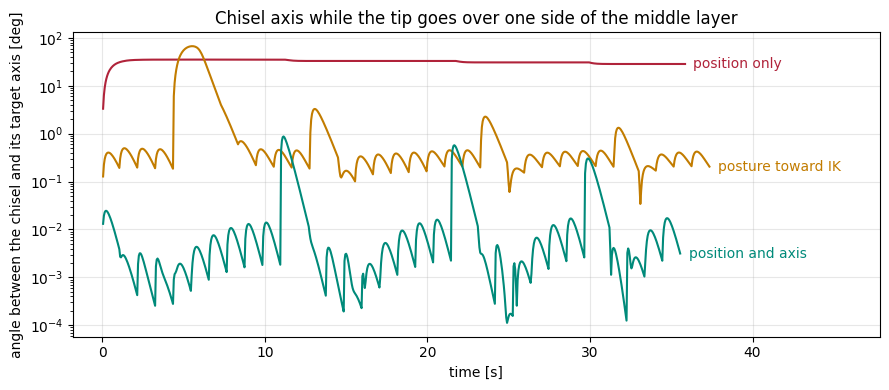

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.grid(alpha=0.3)
for name, color in VARIANT_COLORS.items():
    e = runs[("middle layer", name)][0]
    t = np.arange(1, len(e) + 1) * DT
    ax.plot(t, e, color=color, lw=1.5)
    ax.annotate(name, (t[-1], e[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=color)
ax.set_yscale("log")
ax.set_xlabel("time [s]")
ax.set_ylabel("angle between the chisel and its target axis [deg]")
ax.set_title("Chisel axis while the tip goes over one side of the middle layer")
ax.set_xlim(right=ax.get_xlim()[1] * 1.22)
fig.tight_layout()
plt.show()

In [7]:
# The move with the most steps in the middle layer and how far its IK pose is from the previous one
ks = segments["middle layer"]
steps = runs[("middle layer", "posture toward IK")][2]
move = int(np.argmax(steps))
print(f"Move {move + 1}: {steps[move]} steps, starts at {steps[:move].sum() * DT:.2f} s, "
      f"IK pose {np.linalg.norm(q_ik[ks[move + 1]] - q_ik[ks[move]]):.2f} rad away from the previous one")

Move 5: 59 steps, starts at 4.35 s, IK pose 3.72 rad away from the previous one


With the position only, the posture task pulls the arm toward $\mathbf{q}_r$, and the chisel turns away from its target direction with it, by $16.10$ degrees in the top layer and $35.24$ in the middle one. With the IK pose as posture the chisel arrives close to its direction ($4.00$ degrees at most), but in the middle layer it turns up to $67.19$ degrees during move 5. The IK pose of that cube is in another configuration of the arm, $3.72$ rad away from the previous one and the posture task drags the whole arm across. With the axis in the task, the chisel stays within $0.87$ degrees, with the same number of steps per cube.

[decision after the professor's answer]